# 01 · Parameter learning

We sample data from a small hybrid network whose conditional distributions we
know exactly, fit every mechanism family NBN has, and measure how far each
learned distribution is from the truth.

- **NBN API:** `NeuralBayesianNetwork`, `auto_mechanisms`, `set_mechanism`,
  `fit` (with `weights=`, `epochs=`, `warm_start=`), `log_prob(per_node=True)`,
  `TrainHistory`, and the mechanisms `CategoricalTableMechanism`,
  `SmoothedEmpiricalCategoricalMechanism`, `NeuralCategoricalMechanism`,
  `BinningCategoricalTable`, `LinearGaussianMechanism`, `MDNMechanism`,
  `NormalizingFlowMechanism`, `ConditionalKDEMechanism`,
  `KNNConditionalMechanism`, `FlexCodeMechanism`.
- **Runtime:** about 25 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"` (includes `zuko` for the flow), then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth (hidden from the learner):

    Rain       ~ Bernoulli(0.3)
    Sprinkler  | Rain             table
    WetGrass   | Rain, Sprinkler  table
    Soil       | WetGrass = 0  ~  N(-1, 0.5^2)
    Soil       | WetGrass = 1  ~  0.5 N(1.5, 0.3^2) + 0.5 N(3, 0.3^2)        (bimodal)
    Growth     | Soil          ~  N(0.8 Soil + 0.5, (0.15 + 0.25 |Soil - 1|)^2)  (noise grows with |Soil - 1|)
    Runoff     | Soil          ~  Bernoulli(sigmoid(3 (Soil - 2.2)))         (discrete child of a continuous node)

Because every true density is known, we can score a learned model by
`KL(true || learned) = E[log p_true(x | pa) - log p_learned(x | pa)]`,
averaged over a large held-out sample (exactly, for the discrete part).

In [1]:
import itertools
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    CategoricalTableMechanism,
    ConditionalKDEMechanism,
    DeterministicMechanism,
    FlexCodeMechanism,
    KNNConditionalMechanism,
    LinearGaussianMechanism,
    MDNMechanism,
    NeuralBayesianNetwork,
    NeuralCategoricalMechanism,
    SmoothedEmpiricalCategoricalMechanism,
    seed_all,
)
from nbn.mechanisms import BinningCategoricalTable, DiracGaussianMechanism, NormalizingFlowMechanism
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6")
GREY, INK = "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The ground truth

`sample(n)` draws rows from the true network; `true_log_prob(rows)` returns
the true `log p(x | pa)` of every node.  The data stay on the CPU; the model
moves them to its own device.

In [2]:
P_RAIN = torch.tensor([0.7, 0.3])
P_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])                     # [rain, sprinkler]
P_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]],                      # [rain, sprinkler, wet]
                      [[0.15, 0.85], [0.02, 0.98]]])
EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass"),
         ("WetGrass", "Soil"), ("Soil", "Growth"), ("Soil", "Runoff")]
VARIABLES = {"Rain": ("discrete", 2), "Sprinkler": ("discrete", 2), "WetGrass": ("discrete", 2),
             "Soil": ("continuous", 1), "Growth": ("continuous", 1), "Runoff": ("discrete", 2)}


def normal_pdf(x, mean, std):
    return torch.exp(-0.5 * ((x - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))


def soil_pdf(x, wet):
    wet_pdf = 0.5 * normal_pdf(x, 1.5, 0.3) + 0.5 * normal_pdf(x, 3.0, 0.3)
    return torch.where(wet == 1, wet_pdf, normal_pdf(x, -1.0, 0.5))


def growth_mean(soil):
    return 0.8 * soil + 0.5


def growth_std(soil):
    return 0.15 + 0.25 * (soil - 1.0).abs()


def p_runoff(soil):
    return torch.sigmoid(3.0 * (soil - 2.2))


def sample(n: int) -> dict:
    rain = torch.multinomial(P_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(P_SPRINKLER[rain, 1]).long()
    wet = torch.bernoulli(P_WET[rain, sprinkler, 1]).long()
    high = torch.rand(n) < 0.5
    soil_wet = torch.where(high, 3.0, 1.5) + 0.3 * torch.randn(n)
    soil = torch.where(wet == 1, soil_wet, -1.0 + 0.5 * torch.randn(n))
    growth = growth_mean(soil) + growth_std(soil) * torch.randn(n)
    runoff = torch.bernoulli(p_runoff(soil)).long()
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet, "Soil": soil[:, None],
            "Growth": growth[:, None], "Runoff": runoff}


def true_log_prob(rows: dict) -> dict:
    r, s, w, ru = rows["Rain"], rows["Sprinkler"], rows["WetGrass"], rows["Runoff"]
    soil, growth = rows["Soil"][:, 0], rows["Growth"][:, 0]
    p = p_runoff(soil)
    return {"Rain": P_RAIN[r].log(), "Sprinkler": P_SPRINKLER[r, s].log(),
            "WetGrass": P_WET[r, s, w].log(), "Soil": soil_pdf(soil, w).log(),
            "Growth": normal_pdf(growth, growth_mean(soil), growth_std(soil)).log(),
            "Runoff": torch.where(ru == 1, p, 1 - p).log()}


seed_all(0)
held_out = sample(20_000)
true_lp = true_log_prob(held_out)
print("held-out rows:", held_out["Rain"].shape[0])
print("true mean log-density per node:", {k: round(float(v.mean()), 3) for k, v in true_lp.items()})

held-out rows: 20000
true mean log-density per node: {'Rain': -0.614, 'Sprinkler': -0.58, 'WetGrass': -0.362, 'Soil': -0.812, 'Growth': -0.735, 'Runoff': -0.186}


## 1. `auto_mechanisms`: sensible defaults in one call

`auto_mechanisms()` gives every discrete node a probability table and every
continuous node a mixture density network (MDN).  A discrete node with a
continuous parent (`Runoff`) cannot index a table by a real number, so it gets
a `BinningCategoricalTable`, which cuts the parent into quantile bins.

`kl_per_node` scores a fitted model: the mean of `log p_true - log p_learned`
over the 20,000 held-out rows, node by node (`log_prob(per_node=True)`).

In [3]:
def kl_per_node(model: NeuralBayesianNetwork) -> dict:
    with torch.no_grad():
        learned = model.log_prob(held_out, per_node=True)
    return {k: float((true_lp[k] - learned[k].cpu()).mean()) for k in true_lp}


seed_all(0)
train = sample(3000)
model = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
model.auto_mechanisms()
history = model.fit(train)
for node, kl in kl_per_node(model).items():
    print(f"{node:10s} {type(model.mechanisms[node]).__name__:24s} KL = {kl:.4f} nats")
print(f"fit time {history.wall_clock_s:.2f} s on {history.device}")
rare = (train["Rain"] == 1) & (train["Sprinkler"] == 1) & (train["WetGrass"] == 0)
print("training rows with Rain=1, Sprinkler=1, WetGrass=0:", int(rare.sum()))

Rain       CategoricalTableMechanism KL = 0.0002 nats
Sprinkler  CategoricalTableMechanism KL = 0.0009 nats
WetGrass   CategoricalTableMechanism KL = 0.0157 nats
Soil       MDNMechanism             KL = 0.0030 nats
Growth     MDNMechanism             KL = 0.0099 nats
Runoff     BinningCategoricalTable  KL = 0.0428 nats
fit time 1.40 s on cpu
training rows with Rain=1, Sprinkler=1, WetGrass=0: 0


The tables and the MDNs are close to the truth.  `WetGrass` has the
largest KL of the three tables, and the reason is one rare state.
`(Rain=1, Sprinkler=1, WetGrass=0)` has true probability
0.3 x 0.1 x 0.02 = 0.0006.  It never occurs in these 3000 training rows, so a
table with `alpha=0` (plain counts) gives it a probability of almost zero.
It occurs about 12 times in the 20,000 held-out rows, and each time costs about
17 nats.  A small pseudo-count (`alpha > 0`) avoids this (section 3).
`Runoff` has the largest KL overall: its 5 bins approximate a smooth curve
by a step function.

## 2. Every mechanism family on the same data

`set_mechanism(node, mech)` chooses the mechanism for one node; nodes left
unset are filled by `auto_mechanisms()`.  We fit each family on the same 2000
training rows.  `consolidate=False` skips the extra pass that only
`update()` needs (see notebook 05).

Discrete families are tried on `WetGrass` (discrete parents) and `Runoff`
(continuous parent); continuous families on `Soil` (bimodal given a discrete
parent) and `Growth` (noise that grows with a continuous parent).
`ConditionalFlowMechanism` is another name for `NormalizingFlowMechanism`.

In [4]:
DISCRETE = {
    "table (alpha=0)": lambda: CategoricalTableMechanism(),
    "smoothed (alpha=1)": lambda: SmoothedEmpiricalCategoricalMechanism(alpha=1.0),
    "neural categorical": lambda: NeuralCategoricalMechanism(n_classes=2),
}
CONTINUOUS = {
    "linear Gaussian": lambda: LinearGaussianMechanism(),
    "MDN": lambda: MDNMechanism(num_components=3),
    "normalizing flow": lambda: NormalizingFlowMechanism(),
    "conditional KDE": lambda: ConditionalKDEMechanism(),
    "k-NN": lambda: KNNConditionalMechanism(),
    "FlexCode": lambda: FlexCodeMechanism(epochs=100),
}
COLORS = {"table (alpha=0)": BLUE, "smoothed (alpha=1)": AQUA, "neural categorical": ORANGE,
          "binning table": YELLOW, "k-NN (discrete)": VIOLET,
          "linear Gaussian": BLUE, "MDN": ORANGE, "normalizing flow": AQUA,
          "conditional KDE": YELLOW, "k-NN": MAGENTA, "FlexCode": GREEN}


def fit_with(mechanisms: dict, rows: dict, **fit_kwargs):
    model = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
    for node, mech in mechanisms.items():
        model.set_mechanism(node, mech)
    model.auto_mechanisms()
    start = time.perf_counter()
    model.fit(rows, consolidate=False, **fit_kwargs)
    return model, time.perf_counter() - start


seed_all(1)
train = sample(2000)
results = {}
runoff_mechs = {"binning table": lambda: BinningCategoricalTable(
                    parent_kinds=[("continuous", 1)], n_bins=5, n_categories=2),
                "neural categorical": lambda: NeuralCategoricalMechanism(n_classes=2),
                "k-NN (discrete)": lambda: KNNConditionalMechanism(discrete_child=True)}
for name, make in DISCRETE.items():
    m, secs = fit_with({"WetGrass": make()}, train)
    results[("WetGrass", name)] = (kl_per_node(m)["WetGrass"], secs)
for name, make in runoff_mechs.items():
    m, secs = fit_with({"Runoff": make()}, train)
    results[("Runoff", name)] = (kl_per_node(m)["Runoff"], secs)
for name, make in CONTINUOUS.items():
    m, secs = fit_with({"Soil": make(), "Growth": make()}, train)
    kl = kl_per_node(m)
    results[("Soil", name)] = (kl["Soil"], secs)
    results[("Growth", name)] = (kl["Growth"], secs)

print(f"{'node':9s} {'mechanism':20s} {'KL (nats)':>9s} {'fit (s)':>8s}")
for (node, name), (kl, secs) in results.items():
    print(f"{node:9s} {name:20s} {kl:9.4f} {secs:8.2f}")

node      mechanism            KL (nats)  fit (s)
WetGrass  table (alpha=0)         0.0002     0.70
WetGrass  smoothed (alpha=1)      0.0003     0.71
WetGrass  neural categorical      0.0001     0.81
Runoff    binning table           0.0445     0.70
Runoff    neural categorical      0.0006     0.81
Runoff    k-NN (discrete)         0.0135     0.70
Soil      linear Gaussian         0.2324     0.00
Growth    linear Gaussian         0.1467     0.00
Soil      MDN                     0.0022     0.61
Growth    MDN                     0.0096     0.61
Soil      normalizing flow        0.0119     0.71
Growth    normalizing flow        0.0415     0.71
Soil      conditional KDE         0.1055     0.02
Growth    conditional KDE         0.1234     0.02
Soil      k-NN                    0.1249     0.01
Growth    k-NN                    0.0448     0.01
Soil      FlexCode                0.0235     0.22
Growth    FlexCode                0.1484     0.22


The fit times include the other nodes (fitted with the defaults), so they
compare families only roughly; notebook 06 times the continuous families on
their own.  The chart shows the KL of each family on each node (shorter bars
are better; the axis is logarithmic).

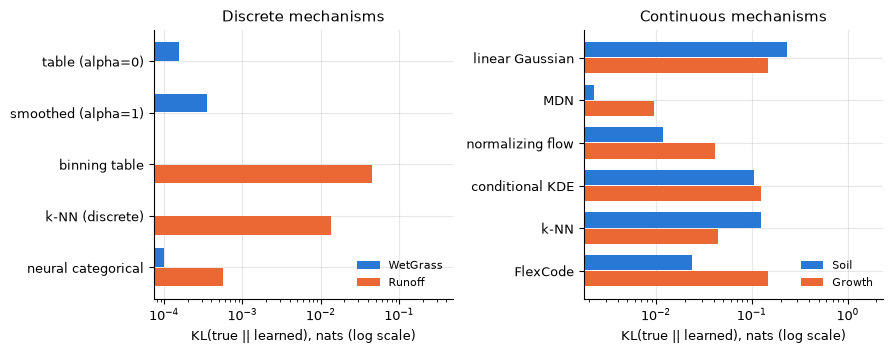

In [5]:
fig, (ax_d, ax_c) = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, nodes, names, colors in ((ax_d, ("WetGrass", "Runoff"),
                                  ["table (alpha=0)", "smoothed (alpha=1)", "binning table",
                                   "k-NN (discrete)", "neural categorical"], (BLUE, ORANGE)),
                                 (ax_c, ("Soil", "Growth"), list(CONTINUOUS), (BLUE, ORANGE))):
    y = np.arange(len(names))
    for j, (node, color) in enumerate(zip(nodes, colors)):
        vals = [results.get((node, n), (np.nan,))[0] for n in names]
        vals = [max(v, 1e-4) for v in vals]
        ax.barh(y + (j - 0.5) * 0.38, vals, height=0.36, color=color, label=node)
    ax.set_yticks(y, names)
    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlim(right=ax.get_xlim()[1] * 8)          # room for the legend
    ax.set_xlabel("KL(true || learned), nats (log scale)")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
ax_d.set_title("Discrete mechanisms")
ax_c.set_title("Continuous mechanisms")
fig.tight_layout()
plt.show()

What to notice: - `WetGrass` has only discrete parents, and all three discrete families are
  close to exact (KL at most 0.0003).
- On `Runoff` the binning table pays for its 5 coarse bins (0.045); k-NN is
  better (0.014), and the neural categorical learns the smooth logistic curve
  almost exactly (0.0006).
- The linear-Gaussian model has one Gaussian per parent value, so it cannot
  fit the bimodal `Soil` or the changing noise of `Growth`: it has the largest
  KL on both.  The MDN is the closest on both nodes.  The flow and FlexCode
  capture the two modes of `Soil` but are less accurate on `Growth`.  With 2000
  rows the KDE and k-NN estimates smooth too much.

`DeterministicMechanism` and `DiracGaussianMechanism` are the two *fixed*
mechanisms: a point mass on a discrete or a continuous value.  They have no
parameters, so `fit` leaves them unchanged.  `intervene()` uses them to clamp a
node (notebook 03); you can also set one by hand for a node whose value is
known by design.

In [6]:
fixed = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
fixed.set_mechanism("Rain", DeterministicMechanism(torch.tensor([1.0]), cardinality=2))  # always rains
fixed.set_mechanism("Soil", DiracGaussianMechanism(2.0))                                # soil fixed at 2.0
fixed.auto_mechanisms()
fixed.fit(train, consolidate=False)
draws = fixed.sample(5)
print("Rain in 5 samples:", to_numpy(draws["Rain"]).ravel().tolist())
print("Soil in 5 samples:", [round(v, 4) for v in to_numpy(draws["Soil"]).ravel().tolist()])

Rain in 5 samples: [1.0, 1.0, 1.0, 1.0, 1.0]
Soil in 5 samples: [2.0, 2.0, 2.0002, 1.9999, 2.0]


## 3. KL against the training-set size

For each size we draw 3 independent training sets (3 seeds), fit, and score.
The lines are the mean over seeds and the bands span the smallest and largest
of the 3 runs.  For the three discrete nodes with discrete parents the KL is
computed exactly, by enumerating their 8 joint states; for `Soil` and `Growth`
it is the held-out estimate.  Neural mechanisms train for `epochs=100` here to
keep the notebook fast.

In [7]:
ENUM = {k: torch.tensor(v) for k, v in zip(("Rain", "Sprinkler", "WetGrass"),
                                          zip(*itertools.product((0, 1), repeat=3)))}
ENUM_P = P_RAIN[ENUM["Rain"]] * P_SPRINKLER[ENUM["Rain"], ENUM["Sprinkler"]] \
    * P_WET[ENUM["Rain"], ENUM["Sprinkler"], ENUM["WetGrass"]]


def learned_joint(model) -> torch.Tensor:
    """Learned P(Rain, Sprinkler, WetGrass) on the 8 joint states, from log_prob."""
    rows = dict(ENUM, Soil=torch.zeros(8, 1), Growth=torch.zeros(8, 1),
                Runoff=torch.zeros(8, dtype=torch.long))      # dummy values: not used below
    with torch.no_grad():
        lp = model.log_prob(rows, per_node=True)
    return (lp["Rain"] + lp["Sprinkler"] + lp["WetGrass"]).exp().cpu()


def exact_discrete_kl(model) -> float:
    return float((ENUM_P * (ENUM_P.log() - learned_joint(model).log())).sum())


SIZES = [100, 300, 1000, 3000]
SEEDS = [0, 1, 2]
CURVE_DISCRETE = ["table (alpha=0)", "smoothed (alpha=1)", "neural categorical"]
CURVE_CONTINUOUS = ["linear Gaussian", "MDN", "normalizing flow", "conditional KDE"]
curves = {name: np.zeros((len(SIZES), len(SEEDS))) for name in CURVE_DISCRETE + CURVE_CONTINUOUS}
start = time.perf_counter()
for i, n in enumerate(SIZES):
    for j, seed in enumerate(SEEDS):
        seed_all(100 + seed)
        rows = sample(n)
        for name in CURVE_DISCRETE:
            mechs = {node: DISCRETE[name]() for node in ("Rain", "Sprinkler", "WetGrass")}
            mechs.update(Soil=LinearGaussianMechanism(), Growth=LinearGaussianMechanism())
            m, _ = fit_with(mechs, rows, epochs=100)
            curves[name][i, j] = exact_discrete_kl(m)
        for name in CURVE_CONTINUOUS:
            m, _ = fit_with({"Soil": CONTINUOUS[name](), "Growth": CONTINUOUS[name]()}, rows,
                            epochs=100)
            kl = kl_per_node(m)
            curves[name][i, j] = kl["Soil"] + kl["Growth"]
print(f"{len(SIZES) * len(SEEDS) * len(curves)} fits in {time.perf_counter() - start:.1f} s")
print(f"{'mechanism':20s}" + "".join(f"{f'n={n}':>10s}" for n in SIZES))
for name, values in curves.items():
    print(f"{name:20s}" + "".join(f"{v:10.4f}" for v in values.mean(axis=1)))

84 fits in 11.7 s
mechanism                n=100     n=300    n=1000    n=3000
table (alpha=0)         0.0563    0.0254    0.0169    0.0012
smoothed (alpha=1)      0.0464    0.0136    0.0031    0.0013
neural categorical      0.0507    0.0123    0.0038    0.0017
linear Gaussian         0.3914    0.3930    0.3835    0.3805
MDN                     0.1932    0.2094    0.0266    0.0119
normalizing flow        0.2869    0.1303    0.1241    0.0644
conditional KDE         0.5897    0.4411    0.2977    0.1910


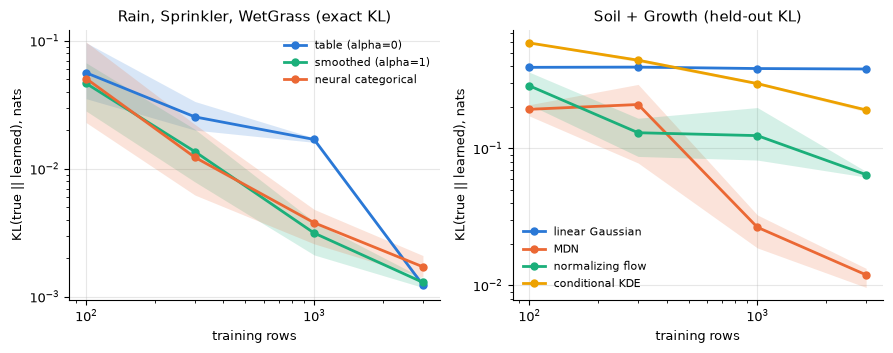

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, names, title in ((axes[0], CURVE_DISCRETE, "Rain, Sprinkler, WetGrass (exact KL)"),
                         (axes[1], CURVE_CONTINUOUS, "Soil + Growth (held-out KL)")):
    for name in names:
        values = curves[name]
        ax.plot(SIZES, values.mean(axis=1), "o-", color=COLORS[name], lw=2, ms=5, label=name)
        ax.fill_between(SIZES, values.min(axis=1), values.max(axis=1), color=COLORS[name],
                        alpha=0.18, lw=0)
    ax.set(xscale="log", yscale="log", xlabel="training rows",
           ylabel="KL(true || learned), nats", title=title)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

Left: the three discrete families converge.  The plain table (`alpha=0`) is
the slowest between 300 and 1000 rows, for the reason seen in section 1: rare
states that are missing from the training set get probability zero.  A
pseudo-count (`SmoothedEmpiricalCategoricalMechanism`) or the neural
categorical does not have this problem.

Right: the linear-Gaussian KL stays at about 0.38 for every size.  Its
family cannot represent the true densities, and more data does not remove
that bias.  The MDN goes from 0.19 to 0.012 nats.  The epoch count is fixed,
so the smallest sets also get the fewest gradient steps; part of the MDN's
error at 100 and 300 rows is undertraining.  The flow improves more slowly,
and the KDE improves slowly but steadily (0.59 to 0.19).

## 4. Weighted fitting: `fit(..., weights=w)`

`weights` are per-row multiplicities: a row with weight 2 counts as two rows.
A typical use is to correct a biased sample.  Here the logger kept every rainy
day but only one dry day in three, so rain is over-represented.  Weighting each
dry row by 3 (the inverse of its keep rate) undoes the bias.

In [9]:
seed_all(2)
pool = sample(9000)
keep = (pool["Rain"] == 1) | (torch.rand(9000) < 1 / 3)
biased = {k: v[keep] for k, v in pool.items()}
w = torch.where(biased["Rain"] == 1, 1.0, 3.0)
print(f"biased sample: {int(keep.sum())} rows, share of rainy rows "
      f"{float(biased['Rain'].float().mean()):.3f} (truth 0.300)")

plain, _ = fit_with({}, biased, epochs=100)
weighted, _ = fit_with({}, biased, epochs=100, weights=w)


def marginals(model) -> dict:
    """P(node = 1) for the three discrete nodes, summed from the learned joint."""
    joint = learned_joint(model)
    return {node: float(joint[ENUM[node] == 1].sum()) for node in ("Rain", "Sprinkler", "WetGrass")}


p_true = {"Rain": 0.3,
          "Sprinkler": float((P_RAIN * P_SPRINKLER[:, 1]).sum()),
          "WetGrass": float((P_RAIN[:, None, None] * P_SPRINKLER[:, :, None] * P_WET).sum((0, 1))[1])}
report = {"unweighted": marginals(plain), "weighted": marginals(weighted)}
print(f"{'':12s}" + "".join(f"{f'P({k}=1)':>16s}" for k in p_true))
print(f"{'truth':12s}" + "".join(f"{v:16.3f}" for v in p_true.values()))
for name, vals in report.items():
    print(f"{name:12s}" + "".join(f"{v:16.3f}" for v in vals.values()))

biased sample: 4778 rows, share of rainy rows 0.555 (truth 0.300)


                   P(Rain=1)  P(Sprinkler=1)   P(WetGrass=1)
truth                  0.300           0.380           0.556
unweighted             0.555           0.284           0.668
weighted               0.293           0.389           0.554


Integer weights are exactly equivalent to repeating rows.  We check it on the
tables: a fit with weight 3 on the dry rows equals a fit on a data set where
each dry row is copied three times.

In [10]:
repeat = torch.where(biased["Rain"] == 1, 1, 3)
copied = {k: v.repeat_interleave(repeat, dim=0) for k, v in biased.items()}
copies, _ = fit_with({}, copied, epochs=100)
diff = float((learned_joint(copies) - learned_joint(weighted)).abs().max())
print(f"largest difference between the two learned P(Rain, Sprinkler, WetGrass): {diff:.1e}")

try:
    fit_with({"Soil": KNNConditionalMechanism()}, biased, weights=w)
except NotImplementedError as err:
    print("k-NN refuses weights before fitting anything:\n ", str(err)[:150], "...")

largest difference between the two learned P(Rain, Sprinkler, WetGrass): 0.0e+00
k-NN refuses weights before fitting anything:
  weights= was given, but these mechanisms do not support per-sample weights: KNNConditionalMechanism at node 'Soil'.  Swap them for a weighting mechani ...


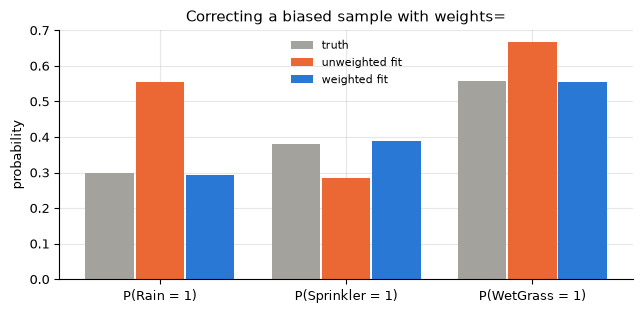

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(len(p_true))
ax.bar(x - 0.27, list(p_true.values()), 0.26, color=GREY, label="truth")
ax.bar(x, list(report["unweighted"].values()), 0.26, color=ORANGE, label="unweighted fit")
ax.bar(x + 0.27, list(report["weighted"].values()), 0.26, color=BLUE, label="weighted fit")
ax.set_xticks(x, [f"P({k} = 1)" for k in p_true])
ax.set(ylabel="probability", title="Correcting a biased sample with weights=")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

The unweighted fit learns the logger's rain rate (0.555 instead of 0.300),
and the error spreads to the other marginals: `P(WetGrass = 1)` is 0.668 instead
of 0.556.  With the weights, the learned rain rate is 0.293, and all three
marginals are within 0.01 of the truth.  The two conditional tables were
never biased: keeping a row depended on `Rain` only.

## 5. Training history and warm starts

`fit` returns a `TrainHistory`: the in-sample mean log-likelihood of every
node (`mean_ll`), the wall-clock time and the device.  It scores the rows the
model was trained on, so it is a fit trace, not a test score.

With `warm_start=True`, `fit` continues from the current parameters instead
of starting again from a random initialisation.  We fit the two MDNs in
rounds of 10 epochs and record, after each round, the in-sample log-likelihood
from `TrainHistory` and the held-out log-likelihood.  The cold runs fit the
same number of epochs per round, but each round starts from scratch.

In [12]:
seed_all(3)
train = sample(2000)
ROUNDS, EPOCHS = 12, 10
true_ll = float((true_lp["Soil"] + true_lp["Growth"]).mean())
trace = {}
for mode in ("warm", "cold"):
    seed_all(4)
    m = NeuralBayesianNetwork(EDGES, VARIABLES, device=device)
    m.set_mechanism("Soil", MDNMechanism(num_components=3))
    m.set_mechanism("Growth", MDNMechanism(num_components=3))
    m.auto_mechanisms()
    in_sample, test = [], []
    for r in range(ROUNDS):
        h = m.fit(train, epochs=EPOCHS, consolidate=False, warm_start=(mode == "warm" and r > 0))
        in_sample.append(h.mean_ll("Soil") + h.mean_ll("Growth"))
        with torch.no_grad():
            lp = m.log_prob(held_out, per_node=True)
        test.append(float((lp["Soil"] + lp["Growth"]).mean()))
    trace[mode] = (in_sample, test)
print("last TrainHistory:", f"wall_clock_s={h.wall_clock_s:.2f}, device={h.device},",
      "nodes:", list(h.node_log_likelihoods))
print(f"true expected log-density of Soil + Growth: {true_ll:.3f}")
for mode, (ins, tst) in trace.items():
    print(f"{mode}: held-out log-lik after round 1 {tst[0]:.3f}, after round {ROUNDS} {tst[-1]:.3f}")

last TrainHistory: wall_clock_s=0.03, device=cpu, nodes: ['Rain', 'Sprinkler', 'WetGrass', 'Soil', 'Growth', 'Runoff']
true expected log-density of Soil + Growth: -1.547
warm: held-out log-lik after round 1 -1.999, after round 12 -1.558
cold: held-out log-lik after round 1 -1.999, after round 12 -1.947


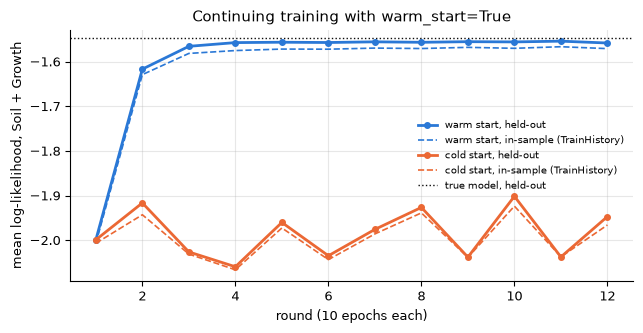

In [13]:
epochs_axis = np.arange(1, ROUNDS + 1)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for mode, color in (("warm", BLUE), ("cold", ORANGE)):
    ins, tst = trace[mode]
    ax.plot(epochs_axis, tst, "o-", color=color, lw=2, ms=4, label=f"{mode} start, held-out")
    ax.plot(epochs_axis, ins, "--", color=color, lw=1.2, label=f"{mode} start, in-sample (TrainHistory)")
ax.axhline(true_ll, color=INK, lw=1, ls=":", label="true model, held-out")
ax.set(xlabel=f"round ({EPOCHS} epochs each)",
       ylabel="mean log-likelihood, Soil + Growth", title="Continuing training with warm_start=True")
ax.legend(frameon=False, fontsize=7, loc="center right")
fig.tight_layout()
plt.show()

With warm starts the held-out log-likelihood climbs from -2.00 to -1.56,
close to the true model's -1.55.  The cold runs start again every round, so
after each round of 10 epochs they are back near -2.0.  The in-sample curve
from `TrainHistory` (dashed) stays close to the held-out curve: with 2000 rows
and 3 mixture components there is little overfitting.